# Внешняя торговля Беларуси: анализ экспорта и импорта важнейших видов продукции (2000–2021)

**Источник:** Белстат, «Экспорт важнейших видов продукции» и «Импорт важнейших видов продукции»
(файлы `export_tovarov_vazh-2021-1.xlsx`, `import_tovarov_vazh-2021-1.xlsx`).

**Что делаем (Задание 1):**
1. Загружаем и чистим данные, проверяем качество.
2. Строим графики и диаграммы: динамика, темпы роста, режимы по периодам, риск/доходность, структура.
3. Ищем зависимости (корреляции темпов роста, пары экспорт/импорт) с поправкой на множественные сравнения.
4. Ищем аномалии (робастный z-score по MAD) и объясняем их.
5. Формулируем выводы (подробный текст — в `README.md`).

> Важно: данные Белстата здесь в **натуральных единицах разных видов** (тыс. т, тыс. шт., тыс. м³, тонны, млн долл.).
> Складывать товары между собой нельзя, поэтому сравниваем **динамику** (индексы, темпы), а не абсолютные объёмы.
> Исключение — блок «структура по массе», где берутся только позиции в тыс. т.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from adjustText import adjust_text
from scipy import stats
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from load_data import FILES, load_all  # noqa: E402

FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
C_EXP, C_IMP = "#1f6fb4", "#e8710a"
CRISIS = [(2008.5, 2009.5, "2009"), (2014.5, 2016.5, "2015–16")]
SRC = "Источник: Белстат; расчёты автора"
ARR = dict(arrowstyle="->", color="#333333", lw=1.1)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()


def fmt_thousands(ax, axis="y"):
    f = mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)

## 1. Загрузка и проверка качества данных

In [2]:
tidy = load_all(save=True)  # сохраняет data/processed/trade_tidy.csv
W = {f: g.pivot(index="year", columns="product_short", values="value") for f, g in tidy.groupby("flow")}
E, I = W["export"], W["import"]
UNITS = tidy.drop_duplicates(["flow", "product_short"]).set_index(["flow", "product_short"])["unit"]
YEARS = E.index

print(f"Экспорт: {E.shape[1]} позиций × {E.shape[0]} лет; импорт: {I.shape[1]} позиций × {I.shape[0]} лет")
print("Период:", YEARS.min(), "-", YEARS.max())
print("Пропусков:", int(tidy["value"].isna().sum()))


def count_text_numbers(path):
    raw = pd.read_excel(path, header=None)
    return int(raw.iloc[4:, 1:].map(lambda x: isinstance(x, str)).sum().sum())


n_text = {k: count_text_numbers(v) for k, v in FILES.items()}
print("Числовых ячеек, хранящихся как текст (с неразрывным пробелом/запятой):", n_text)

# значения с «лишними» знаками после запятой (признак пересчёта/оценки, а не первичной публикации)
for flow, D in W.items():
    frac = (D * 10 - np.round(D * 10)).abs() > 1e-6
    # легковые авто в экспорте даны в штуках (пересчитаны в тыс. шт.) — для них проверка не имеет смысла
    hits = [(c, int(y), D.loc[y, c]) for c in D for y in D.index if frac.loc[y, c] and c != "Легковые авто"]
    print(flow, "— значения с точностью выше 0.1:", hits)

print("\nЕдиницы измерения по позициям:")
print(tidy.drop_duplicates(["flow", "product_short"])[["flow", "product_short", "unit"]].to_string(index=False))

Экспорт: 19 позиций × 22 лет; импорт: 13 позиций × 22 лет
Период: 2000 - 2021
Пропусков: 0
Числовых ячеек, хранящихся как текст (с неразрывным пробелом/запятой): {'export': 40, 'import': 66}
export — значения с точностью выше 0.1: [('Говядина', 2019, np.float64(140.165447)), ('Мясо птицы', 2019, np.float64(170.371655))]
import — значения с точностью выше 0.1: []

Единицы измерения по позициям:
  flow        product_short           unit
export   Пластмассовая тара         тыс. т
export        Пиломатериалы        тыс. м3
export                  ДСП        тыс. м3
export  Хим. волокна и нити         тыс. т
export       Чёрные металлы         тыс. т
export         Холодильники       тыс. шт.
export     Провода и кабели         тыс. т
export          С/х техника       тыс. шт.
export        Легковые авто       тыс. шт.
export         Автозапчасти         тыс. т
export               Мебель млн. долл. США
export            Лекарства           тонн
export             Говядина         тыс. т
e

**Замечания по качеству данных**
- Пропусков нет; но **106 числовых ячеек (≈15%) хранятся как текст** (`'1 196,8'`: 40 в экспорте и 66 в импорте) — нужна нормализация (сделана в `src/load_data.py`).
- Экспорт легковых авто дан в **штуках**, импорт — в **тыс. шт.**: приведено к тыс. шт.
- «Мебель» в экспорте — это **стоимость** (млн долл. США), а не физический объём: сравнивать её с другими нужно осторожно.
- Значения 2019 г. по говядине и мясу птицы имеют «лишние» знаки (140,165447 и 170,371655) — вероятно, пересчёт/уточнение; на выводы не влияет.
- Набор товаров **разный** в экспорте (19) и импорте (13), общих позиций всего 4: лекарства, чёрные металлы, автозапчасти, легковые авто.

## 2. Сводная таблица показателей по каждой позиции
CAGR — среднегодовой темп роста; волатильность — стандартное отклонение лог-темпов роста (ln(x_t/x_{t-1}));
тау Кендалла — непараметрический тест монотонного тренда.

In [3]:


def summarize(D, flow):
    rows = []
    for c in D:
        s = D[c]
        tau, p = stats.kendalltau(s.index, s.values)
        lg = np.log(s).diff().dropna()
        rows.append(
            dict(
                flow=flow,
                product=c,
                unit=UNITS[(flow, c)],
                v2000=s.loc[2000],
                v2008=s.loc[2008],
                v2021=s.loc[2021],
                times_2021_vs_2000=s.loc[2021] / s.loc[2000],
                cagr_2000_21=(s.loc[2021] / s.loc[2000]) ** (1 / 21) - 1,
                cagr_2008_21=(s.loc[2021] / s.loc[2008]) ** (1 / 13) - 1,
                yoy_2021=s.loc[2021] / s.loc[2020] - 1,
                peak_year=int(s.idxmax()),
                vs_peak_2021=s.loc[2021] / s.max() - 1,
                volatility=lg.std(),
                kendall_tau=tau,
                kendall_p=p,
            )
        )
    out = pd.DataFrame(rows)

    def trend_class(r):
        if r.kendall_tau >= 0.6 and r.kendall_p < 0.01 and r.vs_peak_2021 > -0.15:
            return "устойчивый рост"
        if r.kendall_tau >= 0.3 and r.vs_peak_2021 <= -0.15:
            return "рост и откат от пика"
        if r.kendall_p < 0.05 and r.kendall_tau < 0:
            return "снижение"
        return "без выраженного тренда"

    out["trend_class"] = out.apply(trend_class, axis=1)
    return out


SUM = pd.concat([summarize(E, "export"), summarize(I, "import")], ignore_index=True)
SUM.to_csv(RES / "summary_table.csv", index=False, encoding="utf-8-sig")
show = SUM.copy()
for col in ["cagr_2000_21", "cagr_2008_21", "yoy_2021", "vs_peak_2021"]:
    show[col] = (show[col] * 100).round(1)
show["volatility"] = (show["volatility"] * 100).round(0)
show["kendall_tau"] = show["kendall_tau"].round(2)
show["kendall_p"] = show["kendall_p"].round(4)
show["times_2021_vs_2000"] = show["times_2021_vs_2000"].round(1)
pd.set_option("display.width", 250, "display.max_columns", 30)
print(
    show[
        ["flow", "product", "unit", "v2000", "v2021", "times_2021_vs_2000", "cagr_2000_21", "cagr_2008_21", "yoy_2021",
         "peak_year", "vs_peak_2021", "volatility", "kendall_tau", "trend_class"]
    ]
    .sort_values(["flow", "cagr_2000_21"], ascending=[True, False])
    .to_string(index=False)
)

  flow              product           unit    v2000     v2021  times_2021_vs_2000  cagr_2000_21  cagr_2008_21  yoy_2021  peak_year  vs_peak_2021  volatility  kendall_tau            trend_class
export     Молоко (несгущ.)         тыс. т    1.700   205.700               121.0          25.7           9.2     -12.3       2015         -36.7        71.0         0.58   рост и откат от пика
export        Легковые авто       тыс. шт.    0.504    58.526               116.1          25.4          43.7      45.8       2011         -48.0       224.0         0.41   рост и откат от пика
export           Мясо птицы         тыс. т    6.800   189.600                27.9          17.2          30.1      -2.3       2020          -2.3        37.0         0.84        устойчивый рост
export             Говядина         тыс. т    6.800   157.400                23.1          16.1           7.6       5.8       2021           0.0        26.0         0.83        устойчивый рост
export        Сыры и творог        

## 3. Кто растёт быстрее всех: CAGR 2000–2021 и 2008–2021

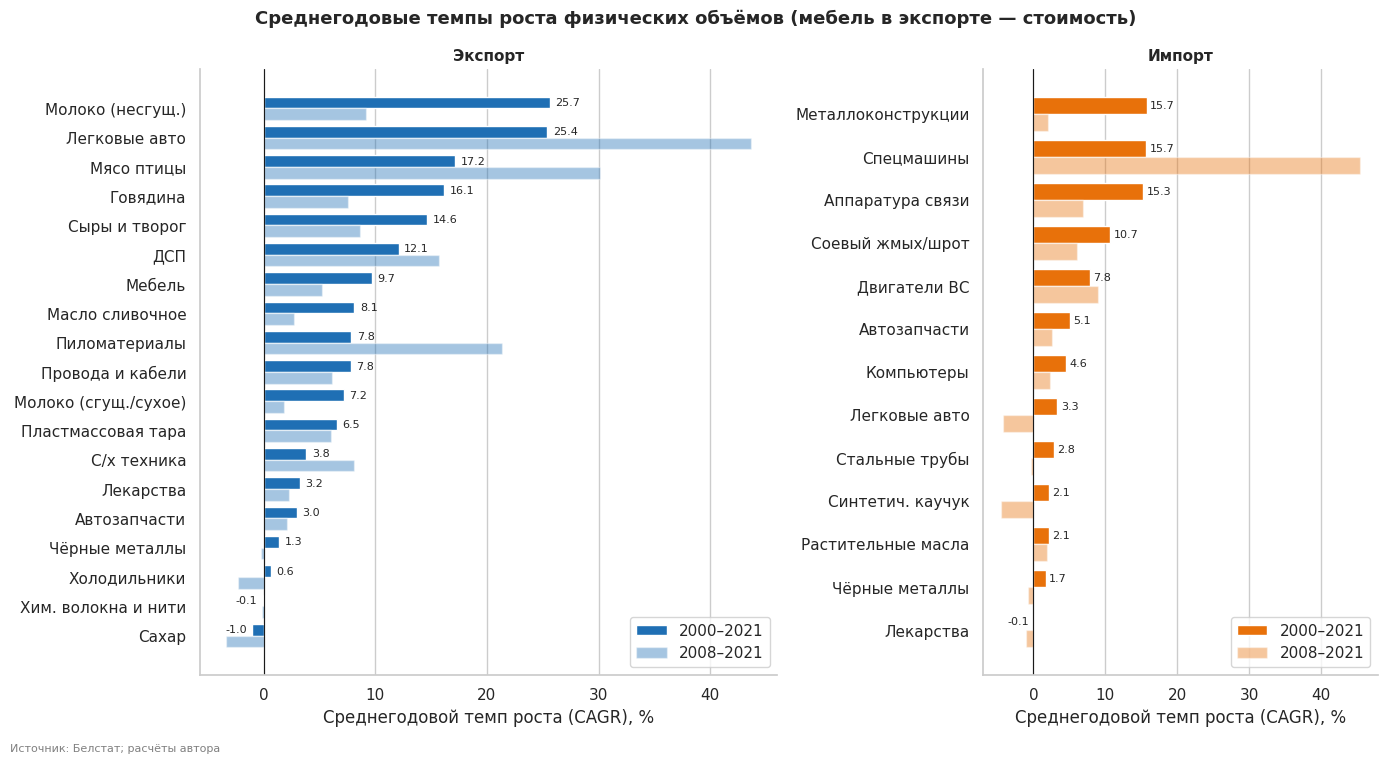

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [19, 13]})
for ax, flow, color in zip(axes, ["export", "import"], [C_EXP, C_IMP]):
    d = SUM[SUM["flow"] == flow].sort_values("cagr_2000_21")
    y = np.arange(len(d))
    ax.barh(y + 0.2, d["cagr_2000_21"] * 100, height=0.4, color=color, label="2000–2021")
    ax.barh(y - 0.2, d["cagr_2008_21"] * 100, height=0.4, color=color, alpha=0.4, label="2008–2021")
    ax.set_yticks(y, d["product"])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("Среднегодовой темп роста (CAGR), %")
    ax.set_title("Экспорт" if flow == "export" else "Импорт")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, d["cagr_2000_21"] * 100):
        ax.text(v + (0.5 if v >= 0 else -0.5), yi + 0.2, f"{v:.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
fig.suptitle("Среднегодовые темпы роста физических объёмов (мебель в экспорте — стоимость)", fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig01_cagr")

**Читаем:** лидеры экспорта по темпам — молоко (+25,7% г/г с очень низкой базы), легковые авто (+25,4%, это отдельная история, см. раздел аномалий),
мясо птицы (+17,2%), говядина (+16,1%), сыры (+14,6%), ДСП (+12,1%). Рост продовольствия идёт «волной» 2000–2015, после 2008 заметно замедлился (CAGR 2008–21 у молочки и говядины — 2–9%).
В импорте самые быстрые — металлоконструкции, спецмашины, аппаратура связи (по +15–16% г/г), но у металлоконструкций рост остановился после 2008 (+2%).

## 4. Динамика каждой позиции (small multiples)
Красная точка — год максимума. Серые полосы — кризисные периоды (2009, 2015–16).

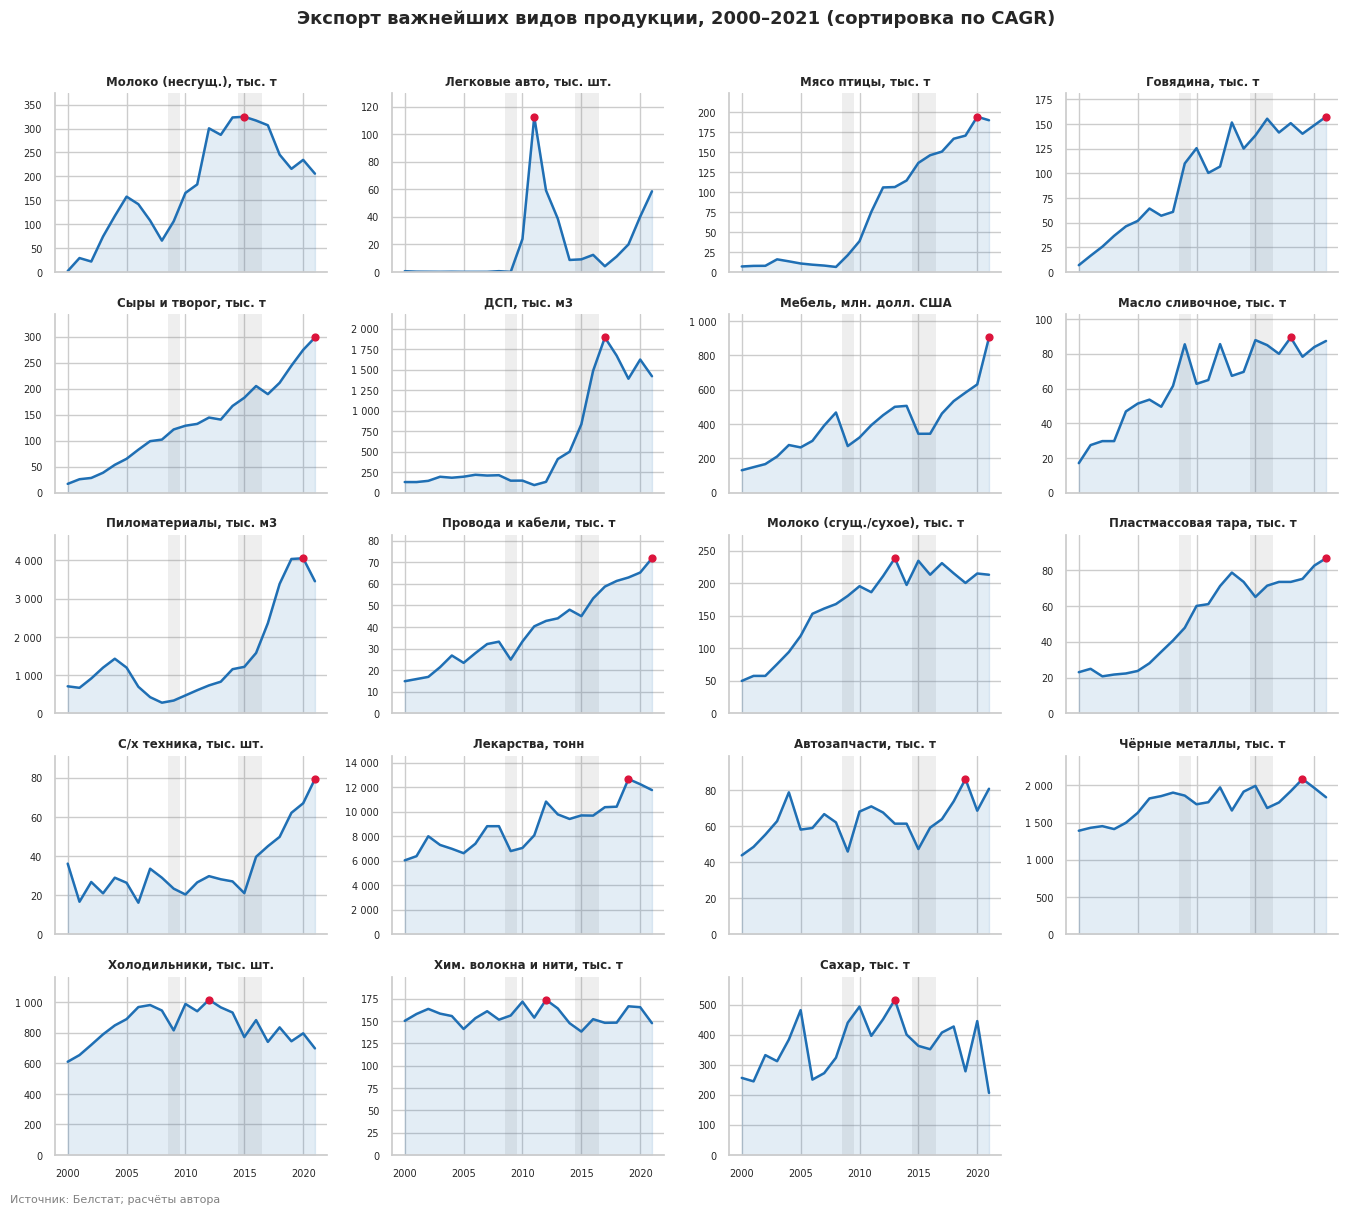

In [5]:
def small_multiples(D, flow, color, ncols, fname, title):
    n = D.shape[1]
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.35 * nrows), sharex=True)
    order = SUM[SUM["flow"] == flow].sort_values("cagr_2000_21", ascending=False)["product"]
    for ax, c in zip(axes.flat, order):
        s = D[c]
        for a, b, _ in CRISIS:
            ax.axvspan(a, b, color="grey", alpha=0.13, lw=0)
        ax.plot(s.index, s.values, color=color, lw=1.8)
        ax.fill_between(s.index, s.values, alpha=0.12, color=color)
        ax.scatter([s.idxmax()], [s.max()], color="crimson", s=24, zorder=3)
        ax.set_title(f"{c}, {UNITS[(flow, c)]}", fontsize=8.5)
        ax.set_ylim(0, s.max() * 1.15)
        ax.tick_params(labelsize=7)
        fmt_thousands(ax)
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.01)
    fig.text(0.01, -0.005, SRC, fontsize=8, color="grey")
    fig.tight_layout()
    save(fig, fname)


small_multiples(E, "export", C_EXP, 4, "fig02_export_series", "Экспорт важнейших видов продукции, 2000–2021 (сортировка по CAGR)")

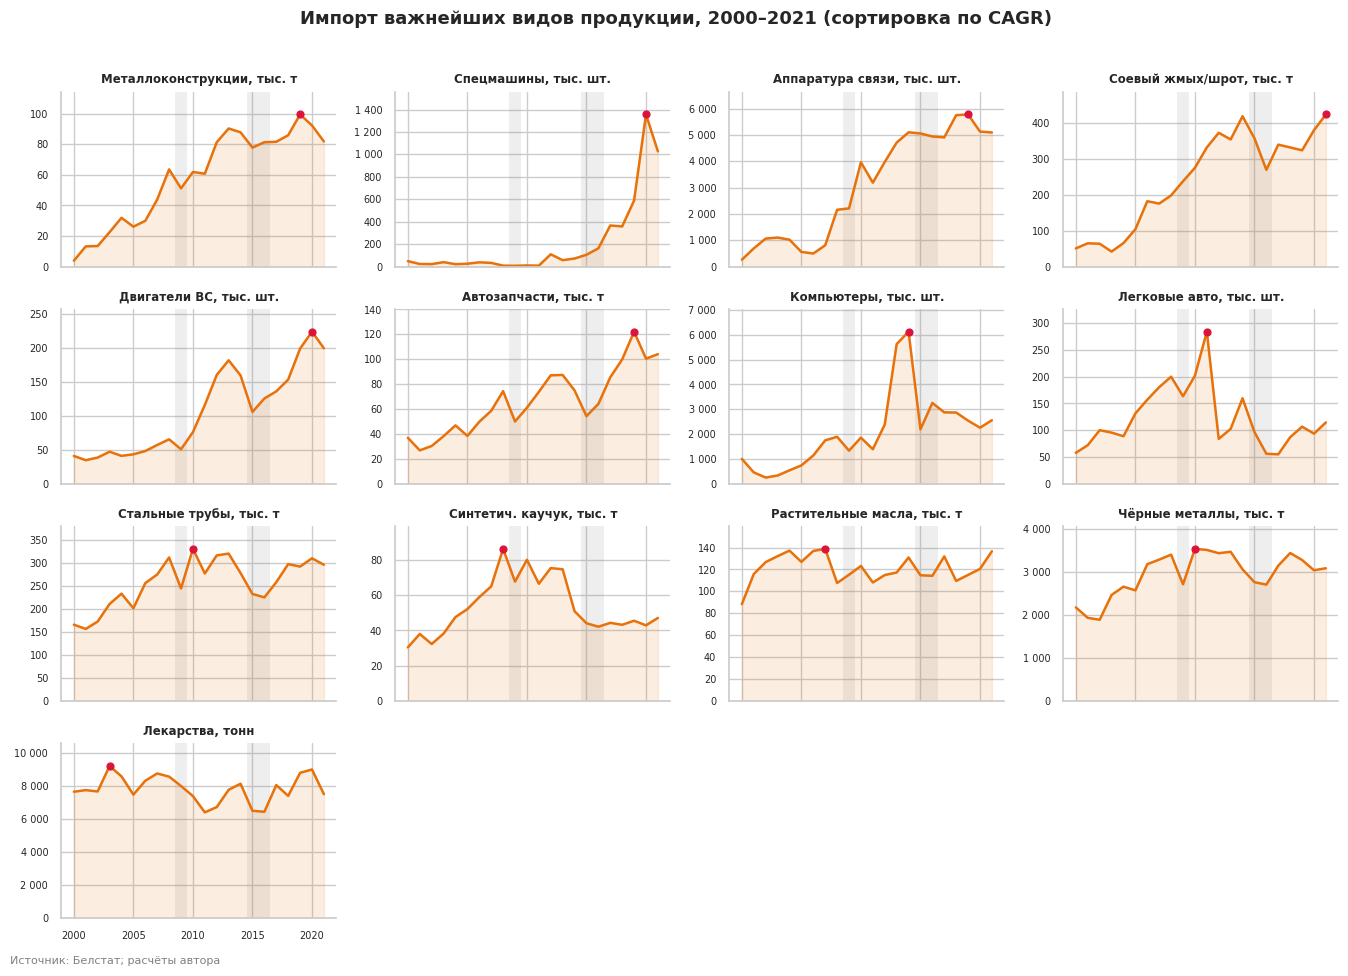

In [6]:
small_multiples(I, "import", C_IMP, 4, "fig03_import_series", "Импорт важнейших видов продукции, 2000–2021 (сортировка по CAGR)")

## 5. Тепловые карты годовых темпов роста
Цвет обрезан на ±60%; в ячейках — фактический % (при |Δ| ≥ 1000% показано «>999»). Видно, какие годы «били» по всему списку товаров сразу.

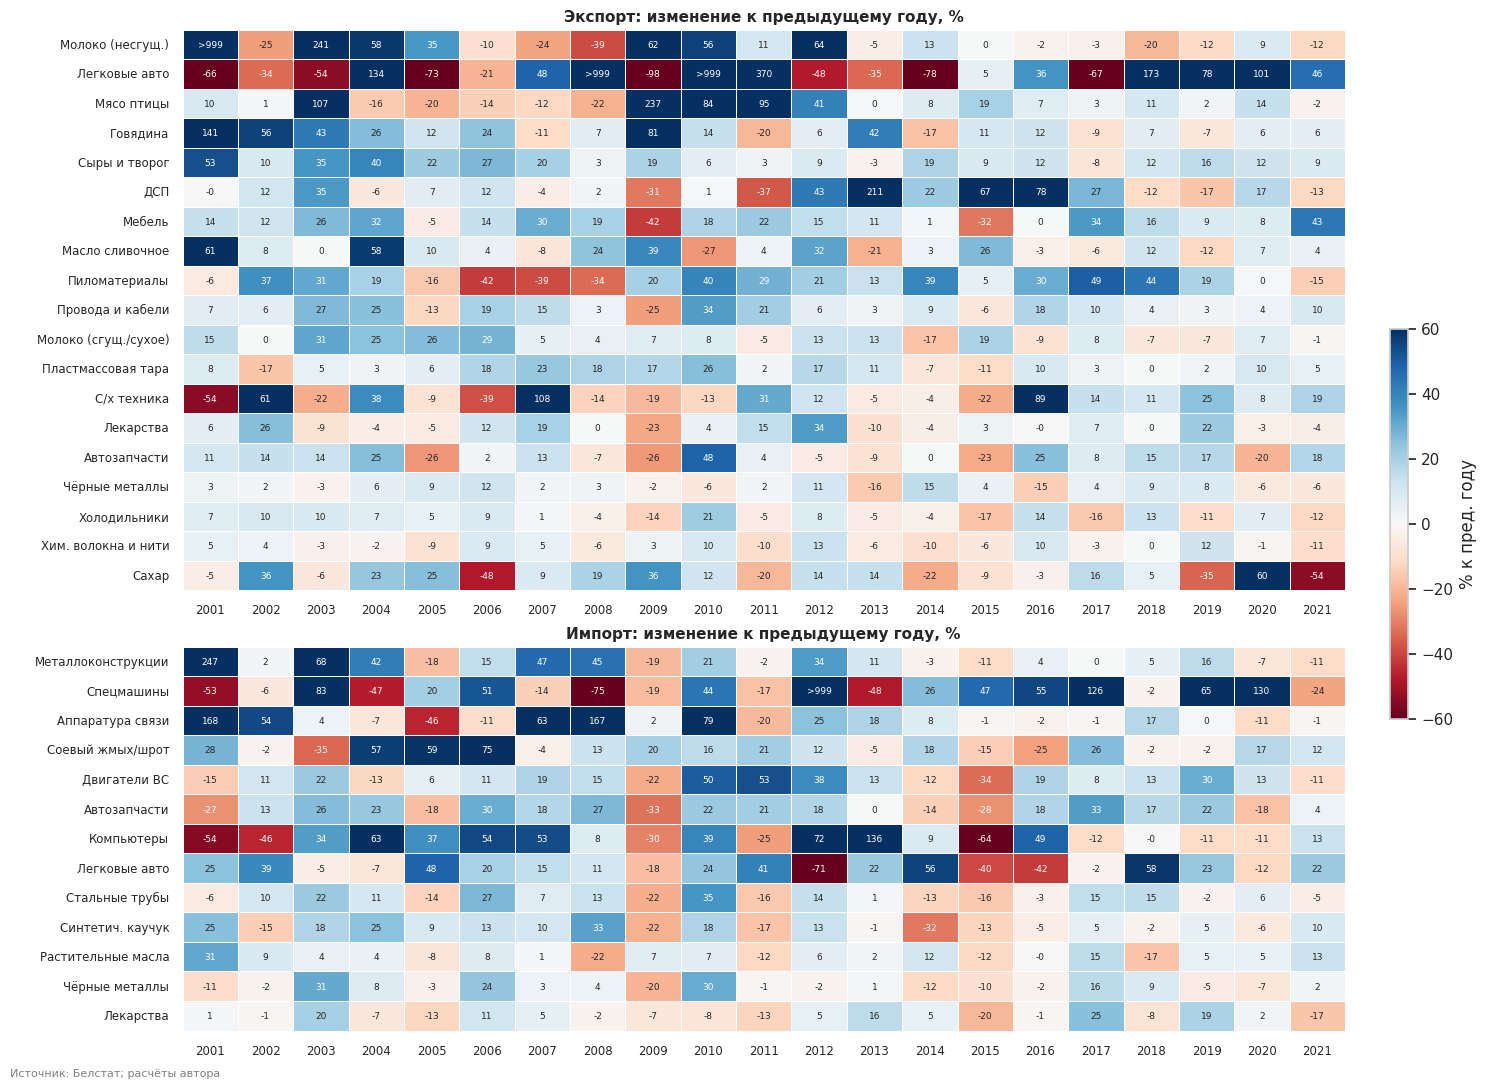

In [7]:
fig, axes = plt.subplots(
    2, 1, figsize=(15, 13), gridspec_kw={"height_ratios": [E.shape[1], I.shape[1]], "hspace": 0.12}
)
norm = mpl.colors.Normalize(vmin=-60, vmax=60)
for ax, D, title in zip(axes, [E, I], ["Экспорт", "Импорт"]):
    G = D.pct_change().iloc[1:] * 100
    order = SUM[SUM["flow"] == ("export" if D is E else "import")].sort_values("cagr_2000_21", ascending=False)["product"]
    G = G[order].T
    annot = G.map(lambda v: ">999" if abs(v) >= 1000 else f"{v:.0f}")
    sns.heatmap(G, ax=ax, cmap="RdBu", norm=norm, annot=annot, fmt="", annot_kws={"fontsize": 6.5}, cbar=False,
                linewidths=0.4, linecolor="white")
    ax.set_title(f"{title}: изменение к предыдущему году, %")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8.5, rotation=0)
    ax.tick_params(axis="x", labelsize=8.5)
cax = fig.add_axes([0.93, 0.35, 0.012, 0.3])
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="RdBu"), cax=cax, label="% к пред. году")
fig.text(0.01, 0.075, SRC, fontsize=8, color="grey")
save(fig, "fig04_growth_heatmap")

## 6. Синхронность: сколько позиций падает в один и тот же год
Если в какой-то год падает почти весь список — причина **внешняя/макроэкономическая**, а не товарная.

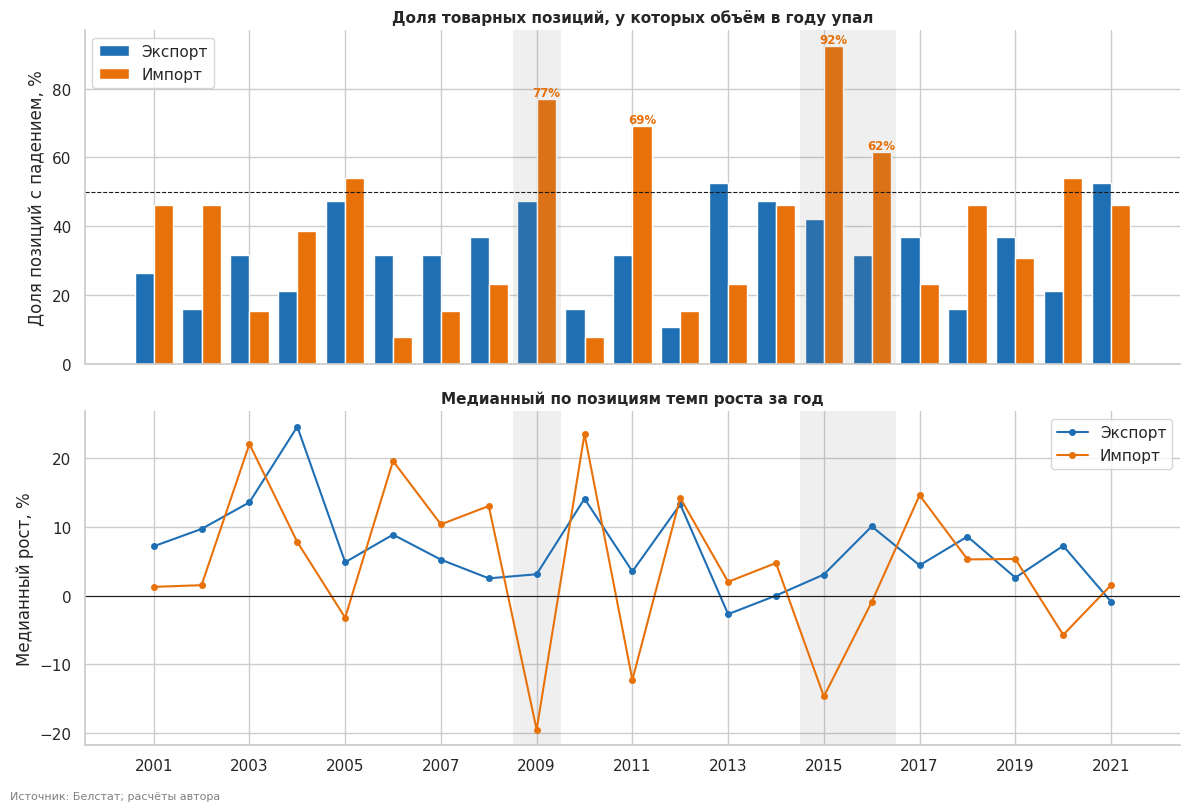

Экспорт: PC1 объясняет 21% вариации темпов роста, PC1+PC2 — 38%
Импорт: PC1 объясняет 34% вариации темпов роста, PC1+PC2 — 50%

Годы, где падала ≥60% позиций:
      Экспорт  Импорт
year                 
2009      NaN    0.77
2011      NaN    0.69
2015      NaN    0.92
2016      NaN    0.62


In [8]:
dec_share = pd.DataFrame(
    {"Экспорт": (E.pct_change() < 0).mean(axis=1), "Импорт": (I.pct_change() < 0).mean(axis=1)}
).iloc[1:]
med_growth = pd.DataFrame(
    {"Экспорт": np.exp(np.log(E).diff().median(axis=1)) - 1, "Импорт": np.exp(np.log(I).diff().median(axis=1)) - 1}
).iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
w = 0.4
x = dec_share.index.values
axes[0].bar(x - w / 2, dec_share["Экспорт"] * 100, w, color=C_EXP, label="Экспорт")
axes[0].bar(x + w / 2, dec_share["Импорт"] * 100, w, color=C_IMP, label="Импорт")
axes[0].axhline(50, color="k", ls="--", lw=0.8)
axes[0].set_ylabel("Доля позиций с падением, %")
axes[0].set_title("Доля товарных позиций, у которых объём в году упал")
axes[0].legend(loc="upper left")
for yr in [2009, 2011, 2015, 2016]:
    axes[0].annotate(f"{dec_share.loc[yr, 'Импорт'] * 100:.0f}%", (yr + w / 2, dec_share.loc[yr, "Импорт"] * 100), ha="center",
                     va="bottom", fontsize=8.5, color=C_IMP, fontweight="bold")
axes[1].plot(med_growth.index, med_growth["Экспорт"] * 100, "-o", color=C_EXP, label="Экспорт", ms=4)
axes[1].plot(med_growth.index, med_growth["Импорт"] * 100, "-o", color=C_IMP, label="Импорт", ms=4)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("Медианный рост, %")
axes[1].set_title("Медианный по позициям темп роста за год")
axes[1].set_xticks(range(2001, 2022, 2))
axes[1].legend(loc="upper right")
for ax in axes:
    for a, b, lab in CRISIS:
        ax.axvspan(a, b, color="grey", alpha=0.12, lw=0)
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig05_synchrony")

# PCA: какая доля вариации темпов роста объясняется одним «общим фактором»
for name, D in [("Экспорт", E), ("Импорт", I)]:
    Z = np.log(D).diff().dropna()
    Z = Z.clip(Z.quantile(0.05), Z.quantile(0.95), axis=1)  # винзоризация от «низкой базы»
    Z = (Z - Z.mean()) / Z.std()
    pca = PCA().fit(Z)
    print(f"{name}: PC1 объясняет {pca.explained_variance_ratio_[0] * 100:.0f}% вариации темпов роста, PC1+PC2 — {pca.explained_variance_ratio_[:2].sum() * 100:.0f}%")
print("\nГоды, где падала ≥60% позиций:")
print(dec_share[(dec_share >= 0.6)].dropna(how="all").round(2))

**Читаем:** импорт гораздо чувствительнее к внешним шокам, чем экспорт (первая главная компонента темпов роста объясняет 34% вариации в импорте против 21% в экспорте). В 2009 г. упало 77% импортных позиций, в 2011 — 69%,
в 2015 — **92%** (т.е. 12 из 13), в 2016 — 62%. Экспорт «рассыпается» намного мягче: максимум 53% (2013 и 2021 г.).
Для экспорта 2009 г. — не провал по всем позициям (47%), потому что кризис ударил по отдельным отраслям (мебель −42%, кабели −25%).

## 7. Режимы роста: CAGR по подпериодам
Три подпериода: 2000–2008 (рост), 2008–2014 (кризис 2009 + «валютный» 2011), 2014–2021 (после девальвации 2014–15 и пандемии).

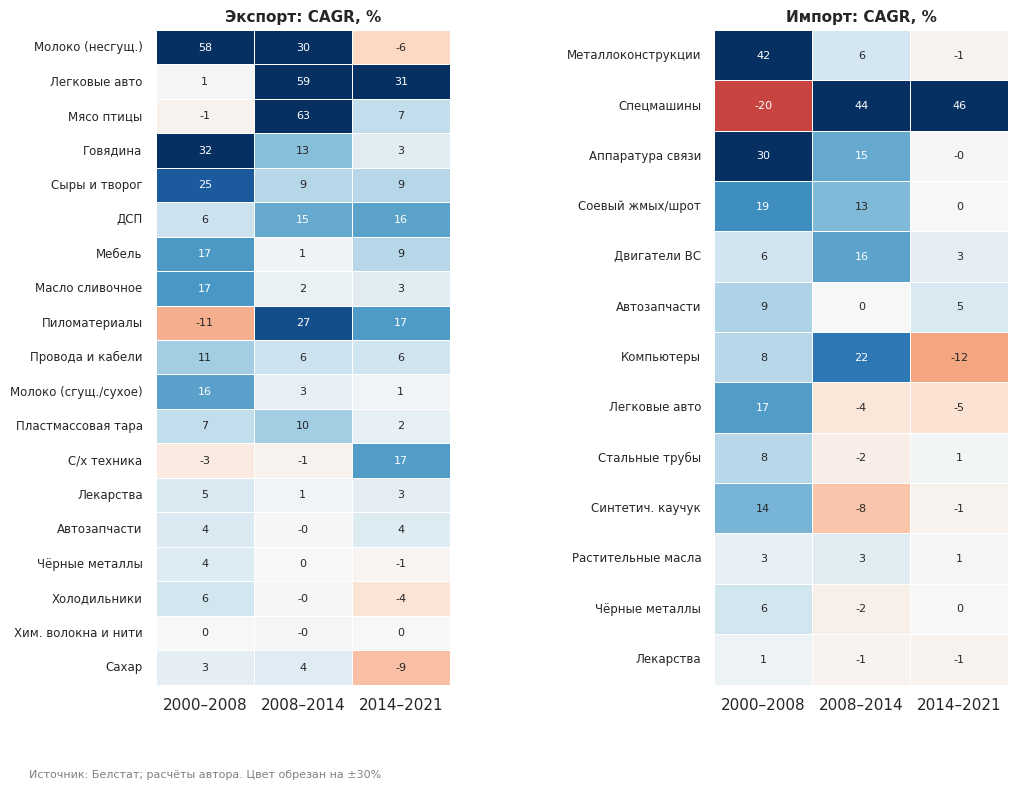

In [9]:
periods = [(2000, 2008), (2008, 2014), (2014, 2021)]
labels = [f"{a}–{b}" for a, b in periods]


def period_cagr(D, flow):
    out = pd.DataFrame({lab: (D.loc[b] / D.loc[a]) ** (1 / (b - a)) - 1 for (a, b), lab in zip(periods, labels)})
    order = SUM[SUM["flow"] == flow].sort_values("cagr_2000_21", ascending=False)["product"]
    return out.loc[order] * 100


fig, axes = plt.subplots(1, 2, figsize=(11, 8.5), gridspec_kw={"width_ratios": [1, 1], "wspace": 0.9})
for ax, D, flow, title in zip(axes, [E, I], ["export", "import"], ["Экспорт", "Импорт"]):
    P = period_cagr(D, flow)
    sns.heatmap(P, ax=ax, cmap="RdBu", center=0, vmin=-30, vmax=30, annot=P.map(lambda v: f"{v:.0f}"), fmt="", cbar=False,
                linewidths=0.5, linecolor="white", annot_kws={"fontsize": 8})
    ax.set_title(f"{title}: CAGR, %")
    ax.tick_params(axis="y", rotation=0, labelsize=8.5)
    ax.set_ylabel("")
fig.text(0.01, 0.0, SRC + ". Цвет обрезан на ±30%", fontsize=8, color="grey")
save(fig, "fig06_period_cagr")

**Читаем:**
- **2000–2008:** рост экспорта держался на молочно-мясном блоке (молоко +58% г/г с крошечной базы, говядина +32%, сыры +25%, масло и мебель +17%);
  пиломатериалы и мясо птицы в этот период не росли. В импорте лидировали металлоконструкции (+42%), аппаратура связи (+30%), соевый шрот (+19%).
- **2008–2014:** экспорт сменил драйверы — мясо птицы (+63%), легковые авто (+59%, реэкспорт), молоко (+30%), пиломатериалы (+27%), ДСП (+15%);
  мебель и автозапчасти встали. В импорте росла «электроника и моторы»: спецмашины (+44%), компьютеры (+22%), двигатели (+16%), аппаратура связи (+15%), а металл, авто и каучук — стагнировали или снижались.
- **2014–2021:** экспорт — ДСП (+16%), пиломатериалы (+17%), с/х техника (+17%), легковые авто (+31%), мебель и сыры (+9%); молоко (−6%), сахар (−9%) и холодильники (−4%) сжимались.
  Импорт почти остановился: у большинства позиций CAGR около нуля, компьютеры −12%; исключение — спецмашины (+46%).

## 8. Доходность против риска: CAGR vs волатильность

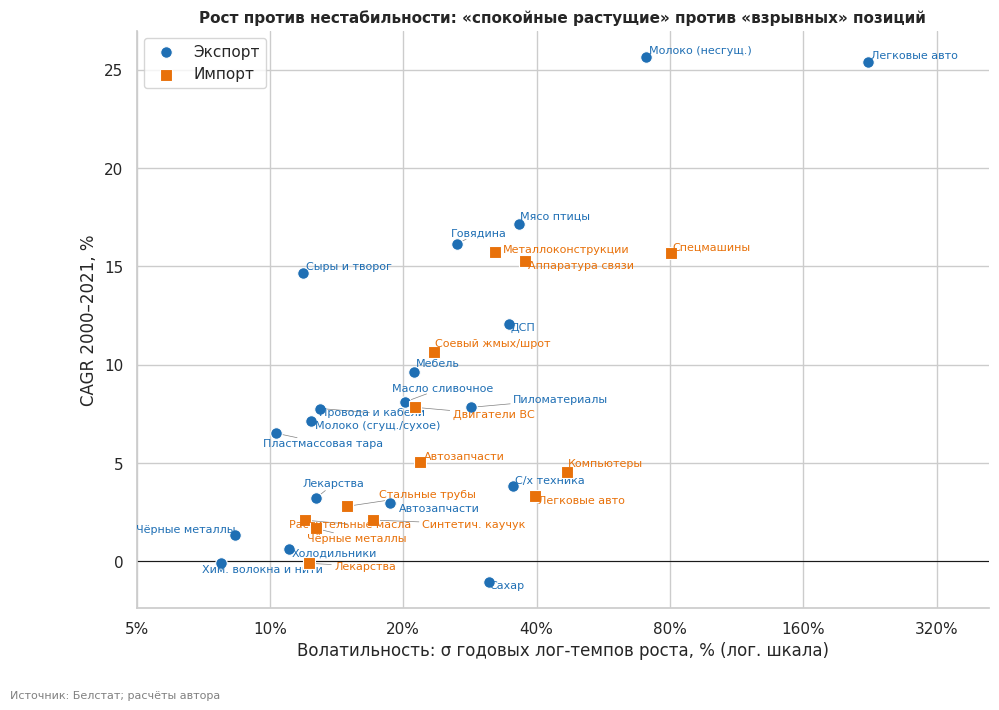

In [10]:
fig, ax = plt.subplots(figsize=(11, 7.5))
texts = []
for flow, color, mk in [("export", C_EXP, "o"), ("import", C_IMP, "s")]:
    d = SUM[SUM["flow"] == flow]
    ax.scatter(d["volatility"] * 100, d["cagr_2000_21"] * 100, s=70, color=color, marker=mk, edgecolor="white", lw=0.8,
               label="Экспорт" if flow == "export" else "Импорт", zorder=3)
    for _, r in d.iterrows():
        texts.append(ax.text(r["volatility"] * 100, r["cagr_2000_21"] * 100, r["product"], fontsize=8, color=color))
ax.set_xscale("log")
ax.axhline(0, color="k", lw=0.8)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xticks([5, 10, 20, 40, 80, 160, 320])
ax.set_xlim(5, 420)
ax.set_xlabel("Волатильность: σ годовых лог-темпов роста, % (лог. шкала)")
ax.set_ylabel("CAGR 2000–2021, %")
ax.set_title("Рост против нестабильности: «спокойные растущие» против «взрывных» позиций")
ax.legend()
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
save(fig, "fig07_risk_return")

**Читаем:** три типа траекторий.
1) *Стабильные «середняки»* (лекарства, чёрные металлы, хим. волокна, растительные масла): CAGR 0–3%, волатильность <20%.
2) *Растущие и сравнительно ровные* (мебель, сыры, провода и кабели, пластмассовая тара): CAGR 6–15%, σ 10–21%.
3) *Взрывные* (σ > 35%): легковые авто (в экспорте σ = 224%, в импорте 40%), спецмашины (80%), молоко (71%), компьютеры (47%), аппаратура связи (38%), мясо птицы (37%), ДСП и с/х техника (35%) — рост «ступенями» и/или эффект низкой базы.

## 9. Сопоставимые позиции: экспорт против импорта
Общих для обоих файлов позиций четыре. Серым закрашено то, где экспорт ≥ импорта (чистый экспортёр в натуральном выражении).

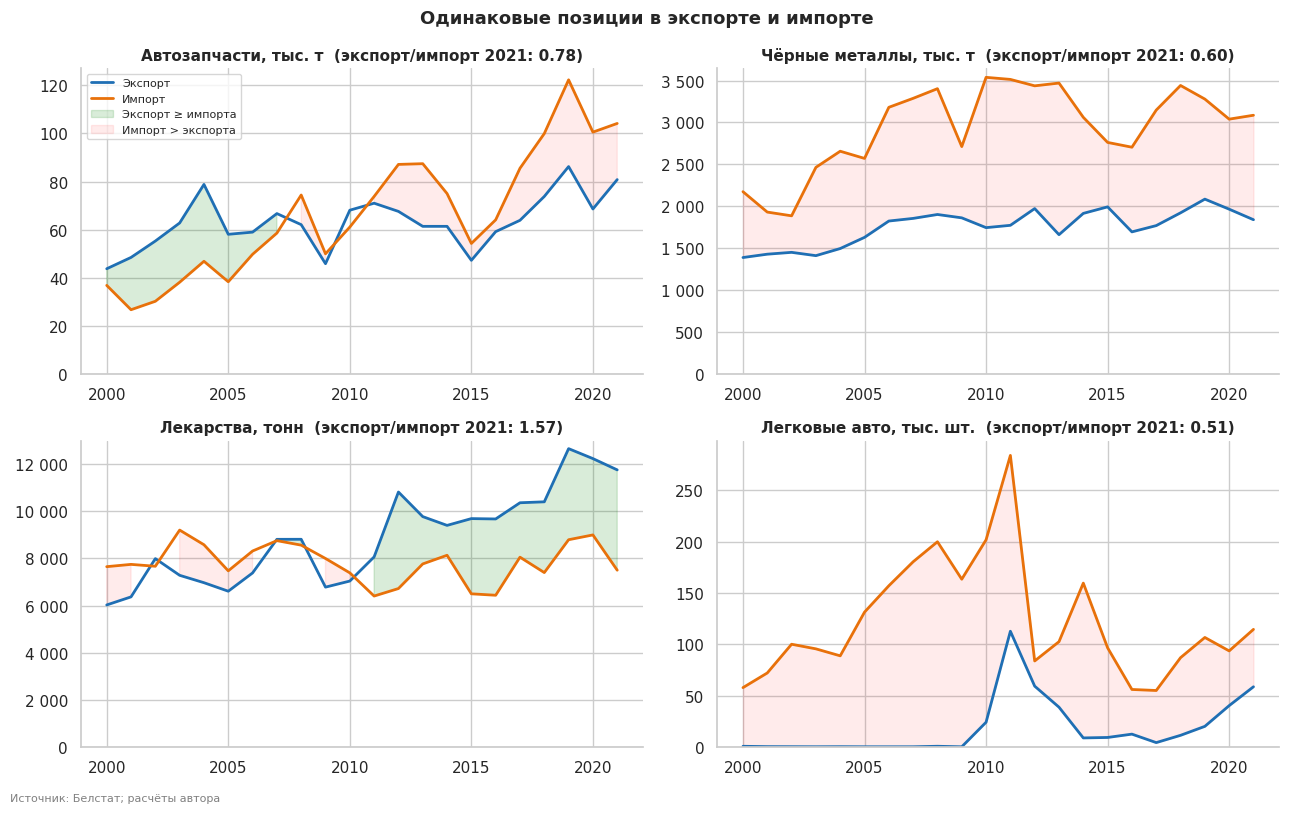

Связь экспорта и импорта одной позиции (по темпам роста и по уровням):
  Автозапчасти    темпы: Spearman ρ=+0.48 (p=0.029) | уровни: Pearson r=+0.71
  Чёрные металлы  темпы: Spearman ρ=-0.10 (p=0.654) | уровни: Pearson r=+0.72
  Лекарства       темпы: Spearman ρ=+0.17 (p=0.457) | уровни: Pearson r=+0.03
  Легковые авто   темпы: Spearman ρ=+0.06 (p=0.788) | уровни: Pearson r=+0.40


In [11]:
common = ["Автозапчасти", "Чёрные металлы", "Лекарства", "Легковые авто"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.flat, common):
    ax.plot(E.index, E[c], color=C_EXP, lw=2, label="Экспорт")
    ax.plot(I.index, I[c], color=C_IMP, lw=2, label="Импорт")
    ax.fill_between(E.index, E[c], I[c], where=E[c] >= I[c], color="green", alpha=0.15, label="Экспорт ≥ импорта")
    ax.fill_between(E.index, E[c], I[c], where=E[c] < I[c], color="red", alpha=0.08, label="Импорт > экспорта")
    ratio = E.loc[2021, c] / I.loc[2021, c]
    ax.set_title(f"{c}, {UNITS[('export', c)]}  (экспорт/импорт 2021: {ratio:.2f})")
    ax.set_ylim(0)
    fmt_thousands(ax)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Одинаковые позиции в экспорте и импорте", fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig08_export_vs_import_common")

lg_E, lg_I = np.log(E).diff().dropna(), np.log(I).diff().dropna()
print("Связь экспорта и импорта одной позиции (по темпам роста и по уровням):")
for c in common:
    rho, p = stats.spearmanr(lg_E[c], lg_I[c])
    r_lvl = np.corrcoef(E[c], I[c])[0, 1]
    print(f"  {c:15s} темпы: Spearman ρ={rho:+.2f} (p={p:.3f}) | уровни: Pearson r={r_lvl:+.2f}")

**Читаем:** Автозапчасти — единственная позиция, где экспорт и импорт «двигаются вместе» и по уровням (r = 0,71), и по темпам роста (ρ = 0,48, p = 0,03) —
признак производственной кооперации/встречных поставок. Для чёрных металлов высокая корреляция **уровней** (0,72) при нулевой корреляции **темпов** (ρ = −0,10)
— классический эффект общего тренда, а не причинная связь. Лекарства: экспорт 2021 (11,8 тыс. т) превышает импорт (7,5 тыс. т) в 1,57 раза — Беларусь по этой позиции чистый экспортёр
в натуральном выражении (ограничение: неясна ценовая структура — это «тонны», а не доллары).

## 10. Зависимости между позициями
Корреляция Спирмена по **годовым лог-темпам роста** (а не по уровням — уровни у трендовых рядов коррелируют «автоматически»).
Из-за множественных сравнений (496 пар) применяем поправку Бенджамини–Хохберга (FDR).

Всего пар: 496; p<0.05 без поправки: 55 (ожидаемо ложных ≈ 25); значимых при FDR 10%: 9
                      a                     b    rho     p  q_fdr
      И: Стальные трубы     И: Чёрные металлы  0.822 0.000  0.002
        И: Автозапчасти     И: Чёрные металлы  0.788 0.000  0.005
  И: Металлоконструкции   И: Синтетич. каучук  0.770 0.000  0.007
              Э: Мебель     И: Чёрные металлы  0.745 0.000  0.013
        И: Автозапчасти     И: Стальные трубы  0.723 0.000  0.021
        Э: Автозапчасти   Э: Провода и кабели  0.674 0.001  0.067
    Э: Провода и кабели     И: Чёрные металлы  0.656 0.001  0.087
              Э: Мебель   Э: Провода и кабели  0.651 0.001  0.087
              Э: Мебель       И: Автозапчасти  0.643 0.002  0.092
    Э: Провода и кабели       И: Автозапчасти  0.605 0.004  0.181
  И: Металлоконструкции     И: Стальные трубы  0.595 0.004  0.201
    И: Аппаратура связи И: Металлоконструкции  0.587 0.005  0.213
        Э: Холодильники     И: Стальные трубы  0.581 0

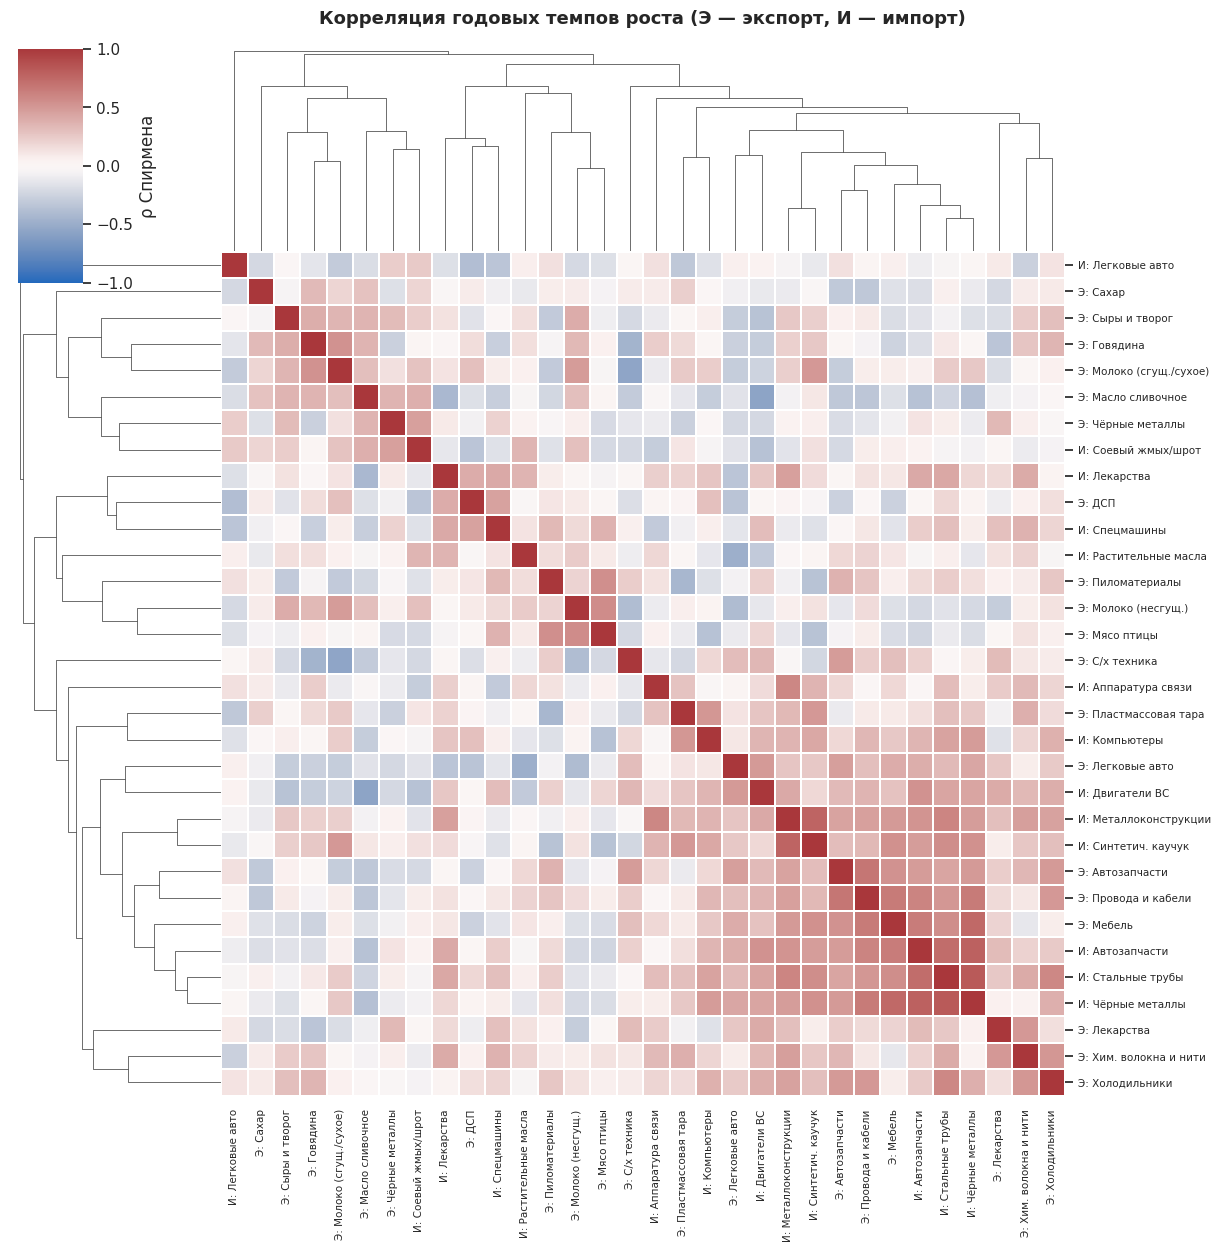

In [12]:
G = pd.concat({"Э": lg_E, "И": lg_I}, axis=1)
G.columns = [f"{a}: {b}" for a, b in G.columns]
rho = G.corr(method="spearman")
n = len(G)
names = list(rho.columns)
rows = []
for i_, a in enumerate(names):
    for b in names[i_ + 1:]:
        r, p = stats.spearmanr(G[a], G[b])
        rows.append((a, b, r, p))
pairs = pd.DataFrame(rows, columns=["a", "b", "rho", "p"])
pairs["q_fdr"] = stats.false_discovery_control(pairs["p"].values, method="bh")
pairs = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).reset_index(drop=True)
pairs.to_csv(RES / "growth_correlations.csv", index=False, encoding="utf-8-sig")
print(f"Всего пар: {len(pairs)}; p<0.05 без поправки: {(pairs.p < 0.05).sum()} (ожидаемо ложных ≈ {0.05 * len(pairs):.0f}); "
      f"значимых при FDR 10%: {(pairs.q_fdr < 0.10).sum()}")
print(pairs.head(15).round(3).to_string(index=False))

dist = 1 - rho.values
link = linkage(squareform(dist, checks=False), "average")
cg = sns.clustermap(rho, row_linkage=link, col_linkage=link, cmap="vlag", center=0, vmin=-1, vmax=1, figsize=(13, 13),
                    xticklabels=True, yticklabels=True, cbar_kws={"label": "ρ Спирмена"}, linewidths=0.2)
cg.ax_heatmap.tick_params(labelsize=7.5)
cg.figure.suptitle("Корреляция годовых темпов роста (Э — экспорт, И — импорт)", y=1.01, fontsize=13, fontweight="bold")
cg.figure.savefig(FIG / "fig09_growth_correlation.png")
plt.show()

## 11. Ложная корреляция: импорт соевого шрота и экспорт мясомолочки
Логичная гипотеза: импорт кормов (соевый жмых/шрот) → рост животноводства → рост экспорта мяса и молока.
Проверяем, выдерживает ли она переход от **уровней** к **темпам роста**.

             product  levels_pearson  growth_spearman  p_growth
            Говядина           0.913            0.021     0.929
          Мясо птицы           0.836           -0.213     0.354
       Сыры и творог           0.876            0.231     0.313
    Молоко (несгущ.)           0.842            0.296     0.192
     Масло сливочное           0.876            0.381     0.089
Молоко (сгущ./сухое)           0.928            0.278     0.223


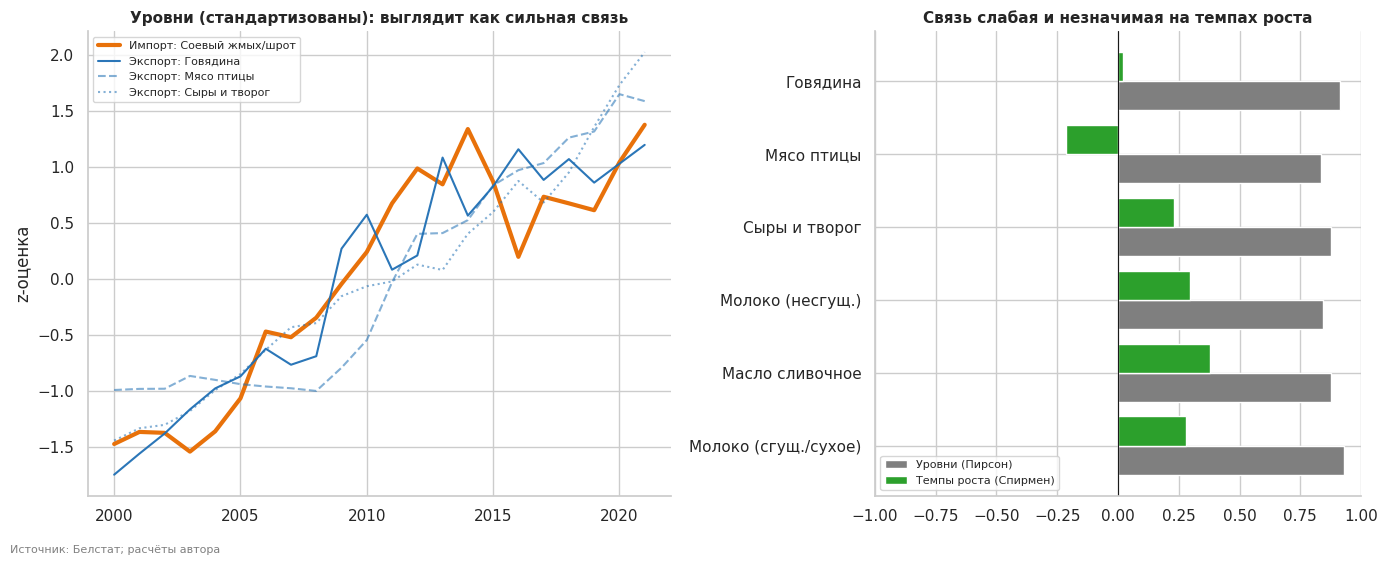

In [13]:
feed = "Соевый жмых/шрот"
targets = ["Говядина", "Мясо птицы", "Сыры и творог", "Молоко (несгущ.)", "Масло сливочное", "Молоко (сгущ./сухое)"]
res = []
for c in targets:
    r_lvl, _ = stats.pearsonr(I[feed], E[c])
    r_g, p_g = stats.spearmanr(lg_I[feed], lg_E[c])
    res.append((c, r_lvl, r_g, p_g))
res = pd.DataFrame(res, columns=["product", "levels_pearson", "growth_spearman", "p_growth"])
print(res.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
z = lambda s: (s - s.mean()) / s.std()
axes[0].plot(I.index, z(I[feed]), color=C_IMP, lw=3, label=f"Импорт: {feed}")
for c in ["Говядина", "Мясо птицы", "Сыры и творог"]:
    axes[0].plot(E.index, z(E[c]), lw=1.5, label=f"Экспорт: {c}", color=C_EXP, alpha=0.55 if c != "Говядина" else 0.95,
                 ls={"Говядина": "-", "Мясо птицы": "--", "Сыры и творог": ":"}[c])
axes[0].set_title("Уровни (стандартизованы): выглядит как сильная связь")
axes[0].set_ylabel("z-оценка")
axes[0].legend(fontsize=8)
yy = np.arange(len(res))
axes[1].barh(yy + 0.2, res["levels_pearson"], 0.4, color="#7f7f7f", label="Уровни (Пирсон)")
axes[1].barh(yy - 0.2, res["growth_spearman"], 0.4, color="#2ca02c", label="Темпы роста (Спирмен)")
axes[1].set_yticks(yy, res["product"])
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlim(-1, 1)
axes[1].invert_yaxis()
axes[1].set_title("Связь слабая и незначимая на темпах роста")
axes[1].legend(loc="lower left", fontsize=8)
fig.text(0.01, -0.02, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig10_spurious_correlation")

**Читаем:** по уровням корреляция 0,84–0,93 (общий восходящий тренд), по темпам роста — от −0,21 до +0,38, и ни одна не значима (все p > 0,08).
То есть **гипотезу «больше кормов → быстрее растёт экспорт мяса» эти данные не подтверждают** — наблюдается лишь одновременный долгосрочный рост.
Это важный методологический вывод: сравнивать нужно приращения/темпы, иначе почти любые две растущие кривые выглядят «связанными».

## 12. Аномалии
Метод: модифицированный z-score по MAD для лог-темпов роста каждого ряда, порог |z| > 3,5 (Иглевич–Хоаглин).
Отдельно помечаем эффект **низкой базы**: предыдущее значение < 10% медианы ряда — тогда «тысячи процентов роста» — арифметика, а не событие.

In [14]:
rows = []
for flow, D, lg in [("export", E, lg_E), ("import", I, lg_I)]:
    for c in D:
        x = lg[c]
        mad = stats.median_abs_deviation(x, scale="normal")
        zsc = (x - x.median()) / mad
        for y in zsc[zsc.abs() > 3.5].index:
            prev = D.loc[y - 1, c]
            rows.append(
                dict(flow=flow, product=c, unit=UNITS[(flow, c)], year=int(y), prev=prev, value=D.loc[y, c],
                     yoy_pct=(np.exp(x[y]) - 1) * 100, z=zsc[y], low_base=prev < 0.10 * D[c].median())
            )
ANOM = pd.DataFrame(rows).sort_values("z", key=abs, ascending=False).reset_index(drop=True)
ANOM.to_csv(RES / "anomalies.csv", index=False, encoding="utf-8-sig")
print(f"Найдено {len(ANOM)} аномальных наблюдений, из них эффект низкой базы: {int(ANOM.low_base.sum())}")
print(ANOM.round(1).to_string(index=False))

Найдено 28 аномальных наблюдений, из них эффект низкой базы: 6
  flow            product           unit  year  prev  value  yoy_pct    z  low_base
export   Молоко (несгущ.)         тыс. т  2001   1.7   29.0   1605.9  8.4      True
export         Мясо птицы         тыс. т  2009   6.2   20.9    237.1  7.2     False
export             Мебель млн. долл. США  2009 467.1  271.5    -41.9 -6.8     False
export      Легковые авто       тыс. шт.  2010   0.0   24.0 299425.0  6.7      True
export   Провода и кабели         тыс. т  2009  33.2   24.9    -25.0 -6.1     False
import Металлоконструкции         тыс. т  2001   3.8   13.2    247.4  5.8      True
export             Мебель млн. долл. США  2015 505.8  343.0    -32.2 -5.3     False
import       Автозапчасти         тыс. т  2009  74.4   50.0    -32.8 -5.0     False
import      Легковые авто       тыс. шт.  2012 284.1   83.7    -70.5 -4.8     False
import Растительные масла         тыс. т  2008 138.8  107.6    -22.5 -4.7     False
import   Аппа

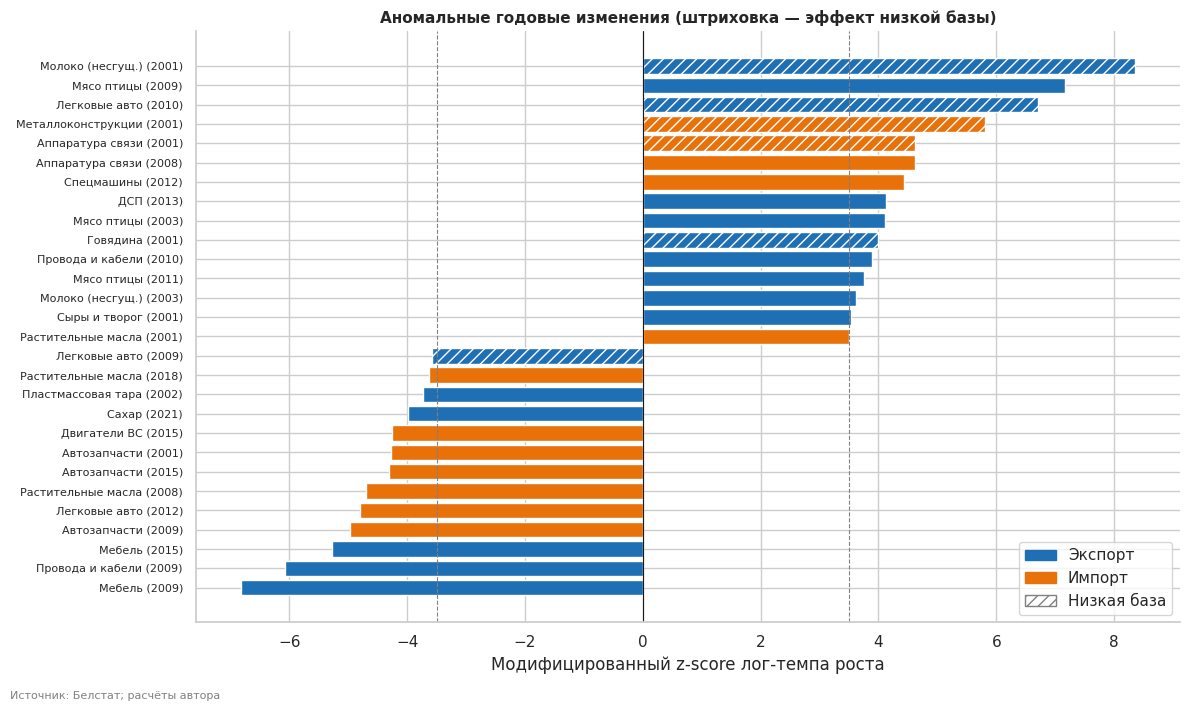

In [15]:
fig, ax = plt.subplots(figsize=(12, 7))
a = ANOM.copy()
a["label"] = a["product"] + " (" + a["year"].astype(str) + ")"
a = a.sort_values("z")
colors = [C_EXP if f == "export" else C_IMP for f in a["flow"]]
bars = ax.barh(a["label"], a["z"], color=colors, hatch=None)
for b_, lb in zip(bars, a["low_base"]):
    if lb:
        b_.set_hatch("///")
        b_.set_edgecolor("white")
ax.axvline(0, color="k", lw=0.8)
ax.axvline(3.5, color="grey", ls="--", lw=0.8)
ax.axvline(-3.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Модифицированный z-score лог-темпа роста")
ax.set_title("Аномальные годовые изменения (штриховка — эффект низкой базы)")
ax.tick_params(axis="y", labelsize=8)
from matplotlib.patches import Patch  # noqa: E402

ax.legend(handles=[Patch(color=C_EXP, label="Экспорт"), Patch(color=C_IMP, label="Импорт"),
                   Patch(facecolor="white", edgecolor="grey", hatch="///", label="Низкая база")], loc="lower right")
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig11_anomalies")

### Ключевые аномалии в контексте

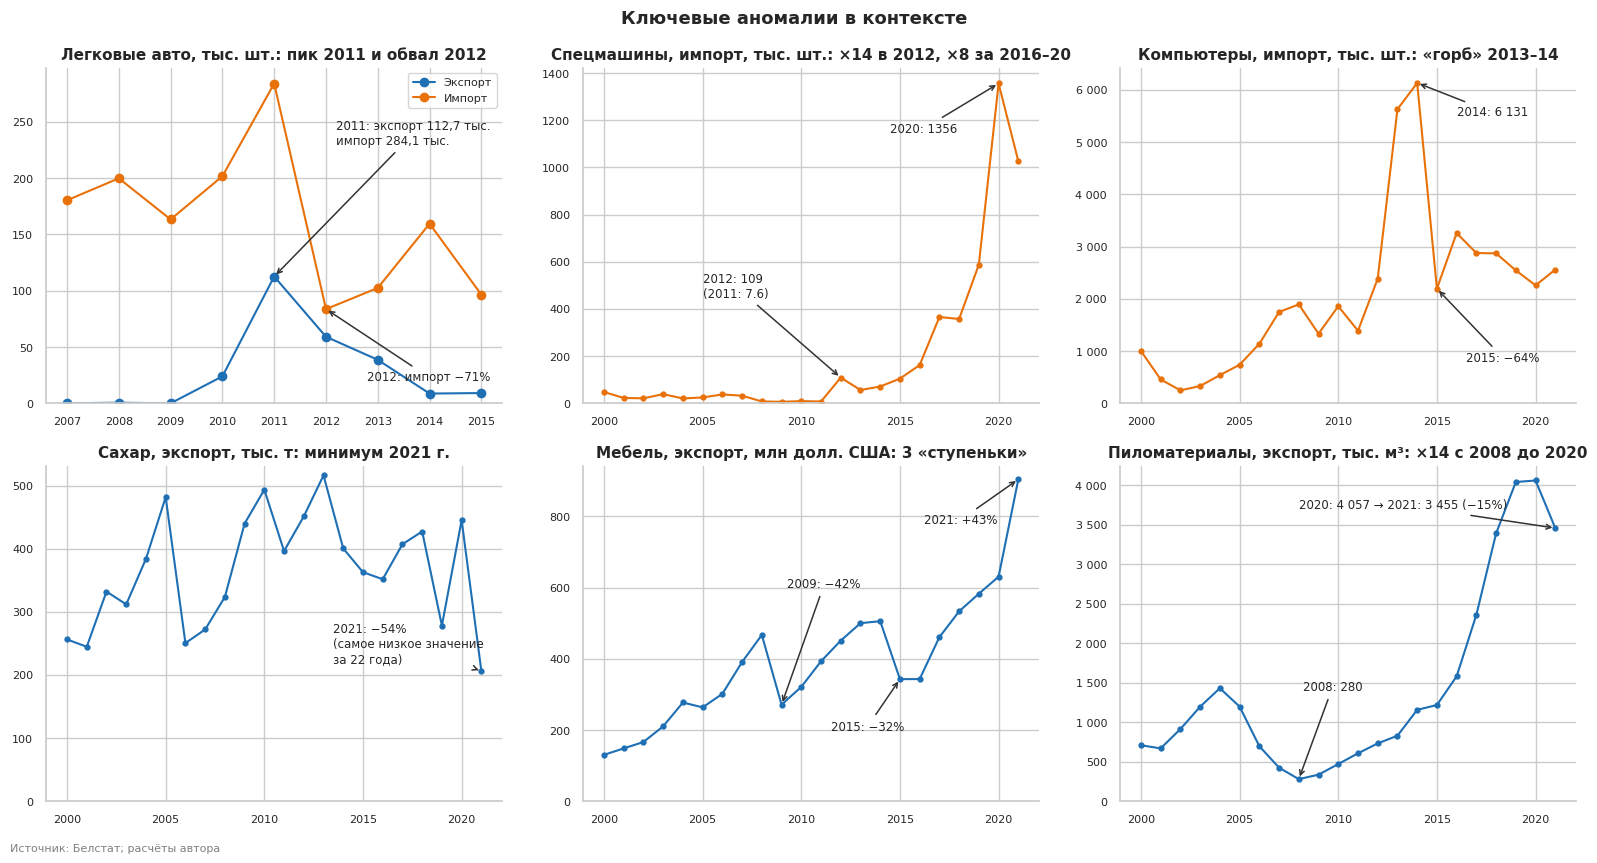

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

# 1. Легковые авто: экспорт vs импорт
ax = axes[0, 0]
sl = slice(2007, 2015)
ax.plot(E.loc[sl].index, E.loc[sl, "Легковые авто"], "-o", color=C_EXP, label="Экспорт")
ax.plot(I.loc[sl].index, I.loc[sl, "Легковые авто"], "-o", color=C_IMP, label="Импорт")
ax.set_title("Легковые авто, тыс. шт.: пик 2011 и обвал 2012")
ax.annotate("2011: экспорт 112,7 тыс.\nимпорт 284,1 тыс.", (2011, 112.654), xytext=(2012.2, 230), arrowprops=ARR, fontsize=8.5)
ax.annotate("2012: импорт −71%", (2012, 83.7), xytext=(2012.8, 20), arrowprops=ARR, fontsize=8.5)
ax.legend(fontsize=8)

# 2. Спецмашины (импорт)
ax = axes[0, 1]
ax.plot(I.index, I["Спецмашины"], "-o", color=C_IMP, ms=3.5)
ax.set_title("Спецмашины, импорт, тыс. шт.: ×14 в 2012, ×8 за 2016–20")
ax.annotate(f"2012: {I.loc[2012, 'Спецмашины']:.0f}\n(2011: {I.loc[2011, 'Спецмашины']:.1f})", (2012, I.loc[2012, "Спецмашины"]),
            xytext=(2005, 450), arrowprops=ARR, fontsize=8.5)
ax.annotate(f"2020: {I.loc[2020, 'Спецмашины']:.0f}", (2020, I.loc[2020, "Спецмашины"]), xytext=(2014.5, 1150), arrowprops=ARR, fontsize=8.5)

# 3. Компьютеры (импорт)
ax = axes[0, 2]
ax.plot(I.index, I["Компьютеры"], "-o", color=C_IMP, ms=3.5)
ax.set_title("Компьютеры, импорт, тыс. шт.: «горб» 2013–14")
ax.annotate(f"2014: {I.loc[2014, 'Компьютеры']:,.0f}".replace(",", " "), (2014, I.loc[2014, "Компьютеры"]), xytext=(2016, 5500), arrowprops=ARR, fontsize=8.5)
ax.annotate("2015: −64%", (2015, I.loc[2015, "Компьютеры"]), xytext=(2016.5, 800), arrowprops=ARR, fontsize=8.5)
fmt_thousands(ax)

# 4. Сахар (экспорт)
ax = axes[1, 0]
ax.plot(E.index, E["Сахар"], "-o", color=C_EXP, ms=3.5)
ax.set_title("Сахар, экспорт, тыс. т: минимум 2021 г.")
ax.annotate("2021: −54%\n(самое низкое значение\nза 22 года)", (2021, E.loc[2021, "Сахар"]), xytext=(2013.5, 220), arrowprops=ARR, fontsize=8.5)

# 5. Мебель (экспорт)
ax = axes[1, 1]
ax.plot(E.index, E["Мебель"], "-o", color=C_EXP, ms=3.5)
ax.set_title("Мебель, экспорт, млн долл. США: 3 «ступеньки»")
ax.annotate("2009: −42%", (2009, E.loc[2009, "Мебель"]), xytext=(2009.3, 600), arrowprops=ARR, fontsize=8.5)
ax.annotate("2015: −32%", (2015, E.loc[2015, "Мебель"]), xytext=(2011.5, 200), arrowprops=ARR, fontsize=8.5)
ax.annotate("2021: +43%", (2021, E.loc[2021, "Мебель"]), xytext=(2016.2, 780), arrowprops=ARR, fontsize=8.5)

# 6. Пиломатериалы (экспорт)
ax = axes[1, 2]
ax.plot(E.index, E["Пиломатериалы"], "-o", color=C_EXP, ms=3.5)
ax.set_title("Пиломатериалы, экспорт, тыс. м³: ×14 с 2008 до 2020")
ax.annotate("2008: 280", (2008, E.loc[2008, "Пиломатериалы"]), xytext=(2008.2, 1400), arrowprops=ARR, fontsize=8.5)
ax.annotate("2020: 4 057 → 2021: 3 455 (−15%)", (2021, E.loc[2021, "Пиломатериалы"]), xytext=(2008, 3700), arrowprops=ARR, fontsize=8.5)
fmt_thousands(ax)

for ax in axes.flat:
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=8)
fig.suptitle("Ключевые аномалии в контексте", fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig12_key_anomalies")

## 13. Структура по массе (только позиции в тыс. т)
Суммировать можно только позиции с одной единицей измерения. Берём все «тыс. т» и группируем.
Это структура **по весу**, а не по стоимости — тяжёлые товары (металл) будут доминировать.

export — доли 2000 / 2021:
       Чёрные металлы  Молочная продукция  Мясо  Сахар  Прочая промышленность
year                                                                        
2000            70.3                 4.3   0.7   13.0                   11.7
2021            51.4                22.4   9.7    5.8                   10.8 

import — доли 2000 / 2021:
       Чёрные металлы и изделия  Корма и масла (для АПК)  Прочее (каучук, автозапчасти)
year                                                                                  
2000                      91.9                      5.4                            2.6
2021                      83.0                     13.4                            3.6 



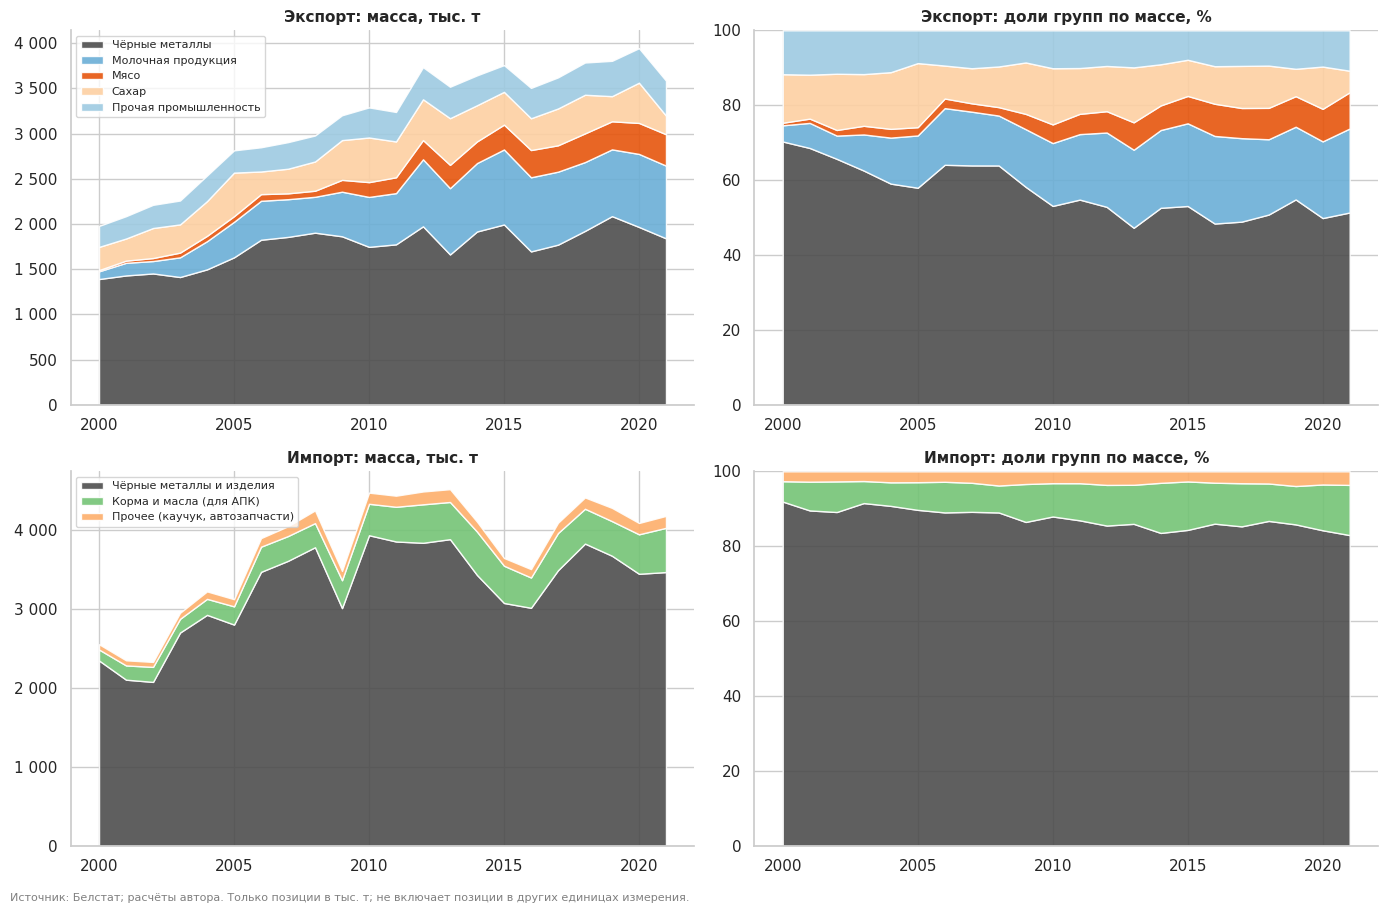

In [17]:
GROUPS_E = {
    "Чёрные металлы": ["Чёрные металлы"],
    "Молочная продукция": ["Молоко (несгущ.)", "Молоко (сгущ./сухое)", "Масло сливочное", "Сыры и творог"],
    "Мясо": ["Говядина", "Мясо птицы"],
    "Сахар": ["Сахар"],
    "Прочая промышленность": ["Пластмассовая тара", "Хим. волокна и нити", "Провода и кабели", "Автозапчасти"],
}
GROUPS_I = {
    "Чёрные металлы и изделия": ["Чёрные металлы", "Стальные трубы", "Металлоконструкции"],
    "Корма и масла (для АПК)": ["Растительные масла", "Соевый жмых/шрот"],
    "Прочее (каучук, автозапчасти)": ["Синтетич. каучук", "Автозапчасти"],
}
pal_e = ["#4d4d4d", "#6baed6", "#e6550d", "#fdd0a2", "#9ecae1"]
pal_i = ["#4d4d4d", "#74c476", "#fdae6b"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (flow, D, groups, pal) in enumerate([("export", E, GROUPS_E, pal_e), ("import", I, GROUPS_I, pal_i)]):
    for g, cols in groups.items():
        assert all(UNITS[(flow, c)] == "тыс. т" for c in cols), (g, cols)
    M = pd.DataFrame({g: D[cols].sum(axis=1) for g, cols in groups.items()})
    axes[row, 0].stackplot(M.index, M.T.values, labels=M.columns, colors=pal, alpha=0.9)
    axes[row, 0].set_title(f"{'Экспорт' if flow == 'export' else 'Импорт'}: масса, тыс. т")
    axes[row, 0].legend(loc="upper left", fontsize=8)
    fmt_thousands(axes[row, 0])
    share = M.div(M.sum(axis=1), axis=0) * 100
    axes[row, 1].stackplot(share.index, share.T.values, labels=share.columns, colors=pal, alpha=0.9)
    axes[row, 1].set_title(f"{'Экспорт' if flow == 'export' else 'Импорт'}: доли групп по массе, %")
    axes[row, 1].set_ylim(0, 100)
    M.to_csv(RES / f"mass_structure_{flow}.csv", encoding="utf-8-sig")
    print(flow, "— доли 2000 / 2021:\n", share.loc[[2000, 2021]].round(1).to_string(), "\n")
fig.text(0.01, -0.01, SRC + ". Только позиции в тыс. т; не включает позиции в других единицах измерения.", fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig13_mass_structure")

**Читаем:** в экспорте (по массе, только позиции в тыс. т) заметно выросли доли мяса и молочной продукции, а чёрные металлы теряют вес;
в импорте по массе стабильно доминируют чёрные металлы и изделия из них, но растёт доля сырья для АПК (соевый шрот и растительные масла) — зеркало роста экспорта животноводческой продукции.

## 14. Итоговые выводы (кратко; развёрнуто — в `README.md`)
1. **Экспорт диверсифицирован и устойчив**, импорт — «хрупкий» и зависит от внешних шоков (2009, 2011, 2015–16).
2. **Продовольственный блок** — главный драйвер экспорта 2000–2015; после 2015 рост молока/масла/сахара остановился, тогда как сыры, мясо птицы, говядина продолжили рост.
3. **Новые драйверы после 2014**: пиломатериалы, ДСП, мебель, с/х техника, провода и кабели.
4. **Аномалии** — это в основном (а) эффект низкой базы 2001–2003, (б) реэкспорт легковых авто 2010–2013, (в) кризисы 2009 и 2015, (г) скачки спецмашин/компьютеров, (д) падение сахара в 2021.
5. **Зависимости**: высокие корреляции уровней — следствие общего тренда; по темпам роста после поправки на множественные сравнения устойчивы только 9 из 496 пар — в основном внутри «металлического» блока импорта (трубы–металл–автозапчасти) плюс связь экспорта мебели с импортом металла (общий деловой цикл).
6. **Ограничение**: нет стоимостных и страновых данных → нельзя оценить сальдо и ценовые эффекты (это отдельная часть заданий 2–3).